# KQC LithographyTestTwoface — optical-lithography resolution, both faces (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/lithography_test_twoface.py` (class `LithographyTestTwoface`, default parameters, chip name "CTest";
© IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/lithography_test_twoface.py`; spec `docs/designs/kqc/test_chips.md`, one
notebook per chip). A process / test chip: the LithographyTest blocks on the bottom chip and six mirrored blocks on the top chip (face 2b1). No qubits or resonators.

This notebook **rebuilds** the chip on the Quantcore PDK — not a replica. We distribute the rebuild under GPL-3.0.
The chip is one KQC chip PCell, so most steps of a circuit notebook (launchers, routes, LOM, FEM, iterate) have
nothing to act on here; each says so.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm; the KQC chip cell is placed with `frames_enabled=[]`, so the Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") replaces KQC's frame |
| pattern | `LithographyTestTwoface.build()` | the same KQC cell with its default parameters, so its own `build()` draws every polygon and label |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 (it changes nothing here: there is no circuit to simulate) |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds); the cell keeps it off its structures with `ground_grid_avoidance` | The original wins: the source has no cheese (KQC's default `with_grid=False`), and the cell puts no `ground_grid_avoidance` on its line patterns, so KQC's grid would perforate them (58 186 holes touched them in a trial build). Chip `cheese: "original"`: no grid and no PDK band. |
| placement | as drawn by KQC | The cell's content sat (+142.6, +670.1) µm off the die centre, so `center_in_die` moves the cell by (−142.6, −670.1) µm. |

**Kept exactly:** the chip is KQC's `LithographyTestTwoface` chip PCell placed once in a 10 × 10 mm Designer chip, with
`frames_enabled=[]`, so KQC's `build()` draws every polygon and label but not its ChipFrame; the Designer chip
draws the Quantcore die frame instead. Fab 2 XORs it with a stand-alone KQC build, which keeps KQC's frame.

**Simplified:** nothing; there are no internal ports or circuit to rebuild element by element.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the empty die, the KQC chip cell placed (and the design saved), the pad-rule check, then views of its parts: the horizontal, vertical and diagonal line blocks of the bottom chip and the top chip's mirrored blocks. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `lithography_test_twoface.v1.ipynb`; both save the same `lithography_test_twoface.json`.

This chip is one KQC PCell with a fixed test pattern and no circuit: the LOM, Simulate and Results steps say in one
sentence each why they do not apply; Check and Fab run as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/lithography_test_twoface/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

On this chip the FEM switches change nothing (it has no sim groups); they are kept so that every design notebook
starts the same way.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/lithography_test_twoface")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip uses the frame, the cheese rule and the fab layer map; it has no junctions and no CPWs.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The whole chip is one KQC PCell, `LithographyTestTwoface`: its `build()` draws the LithographyTest line blocks on the bottom chip and six mirrored blocks on the top chip in one piece. The layout
cannot be split into segments without redrawing that cell (a redesign, not a rebuild), so the segments are the
empty die, the cell placed (and the design saved there, before any picture of it, as in the v1), the pad check, and
then views of its parts with the numbers that make them. The views after Design 2 are zooms of its build (no rebuild).

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (device ID CTest), no cheese (`cheese: "original"`, the PDK-band alternative kept as a comment) |
| 2 | the whole chip: KQC's `LithographyTestTwoface` cell at the origin with KQC's frames off, the centring check, the save |
| 3 | bond pads: none on this chip (the pad-rule check) |
| 4 | a view: the horizontal line blocks (bottom chip) |
| 5 | a view: the vertical line blocks (bottom chip) |
| 6 | a view: the diagonal line blocks (bottom chip) |
| 7 | a view: the top chip's mirrored blocks (face 2b1) |

## Design 1 · The empty die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the name "CTest" (the device ID). The original wins: the source has no cheese (KQC's default `with_grid=False`), and the cell puts no `ground_grid_avoidance` on its line patterns, so KQC's grid would perforate them (58 186 holes touched them in a trial build). Chip `cheese: "original"`: no grid and no PDK band. To maintain the PDK, the cheese code is kept: the commented-out `Designer(...)` call under the cell's first line is the same with `"cheese": "pdk"` (the PDK band: 8922 holes in a probe, none on the test patterns).

The picture is the die with nothing on it but the Quantcore frame (L dicing markers on 1000/0, 3 × 3 alignment grids on
1001/0, the chip boundary on 100/0).

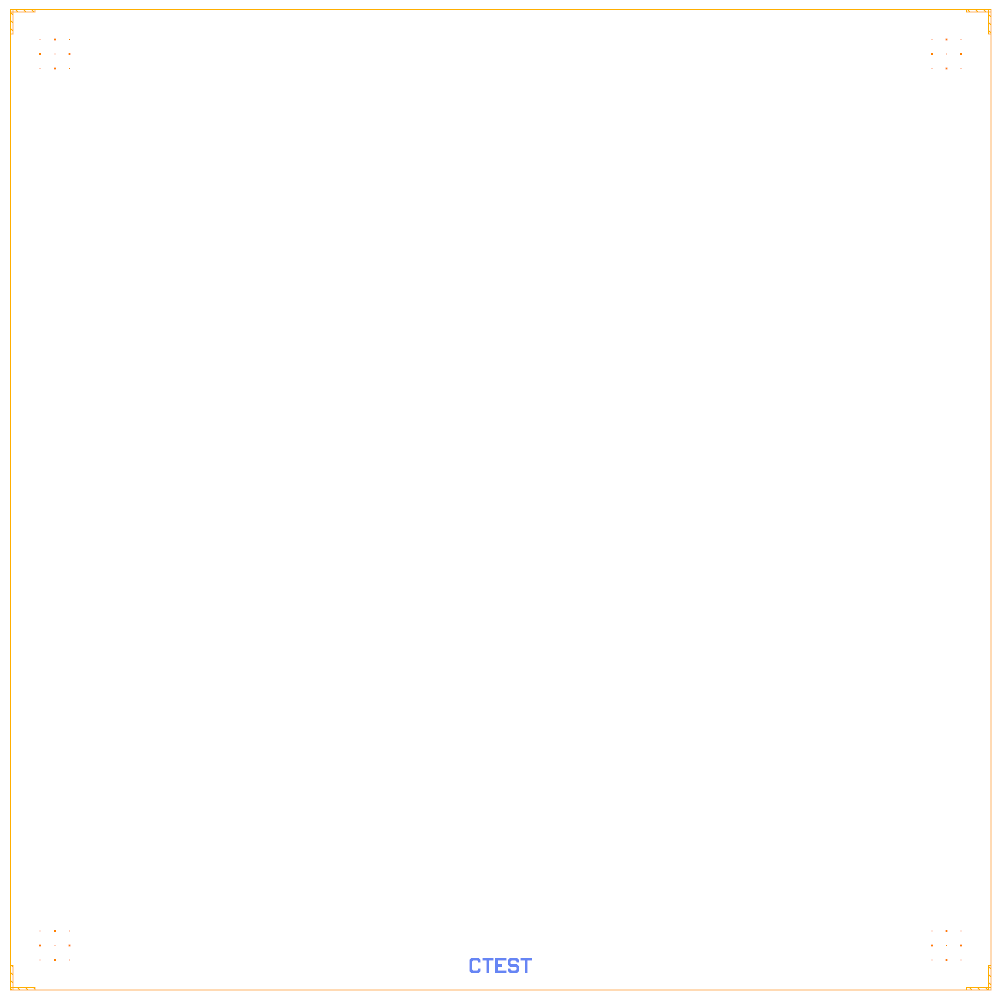

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/lithography_test_twoface/s1_die.png')

In [5]:
d = Designer("lithography_test_twoface", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "cheese": "original"}, live=LIVE)
# No cheese here: the process-test patterns need none. The PDK band (kept for the PDK, not used) is the same call with
# "cheese": "pdk"; it would put 5 µm holes round the 3/0 keep-out and none on the test patterns:
# d = Designer("lithography_test_twoface", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "cheese": "pdk"}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "s1_die.png", **CHIP)

## Design 2 · The chip cell: `LithographyTestTwoface`, placed once, and the save

The whole design is one instance: KQC's `LithographyTestTwoface` chip PCell at the chip origin with `frames_enabled=[]`, so KQC draws
no `ChipFrame` and the Designer chip draws the Quantcore die frame (L dicing markers on 1000/0, 3 × 3 alignment
grids on 1001/0, the chip boundary on 100/0). `center_in_die` then checks that the cell's content sits centred in the
die and moves the cell if it is more than 50 µm off. The cell's content sat (+142.6, +670.1) µm off the die centre, so `center_in_die` moves the cell by (−142.6, −670.1) µm. Then the design is saved with `save_design`, which compares it with the file it replaces (the previous run's):
it should say *same design*. `lithography_test_twoface.json` is what the DRC, the fab export and `qcc` read.

The save comes before any picture of the chip, as in the v1. The picture is the whole chip; the table lists the
cell's own parameters (KQC `get_schema`) with the value this design passes where it passes one. `X0, Y0` (the cell's
origin after the centring) place the views below.

centring shift (µm): (-142.6, -670.1)


**Same design as before:** `examples/designs/kqc/test_chips/lithography_test_twoface.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer lithography_test_twoface: 1 instances, 0 routes, live=False> → examples\designs\kqc\test_chips\lithography_test_twoface.json


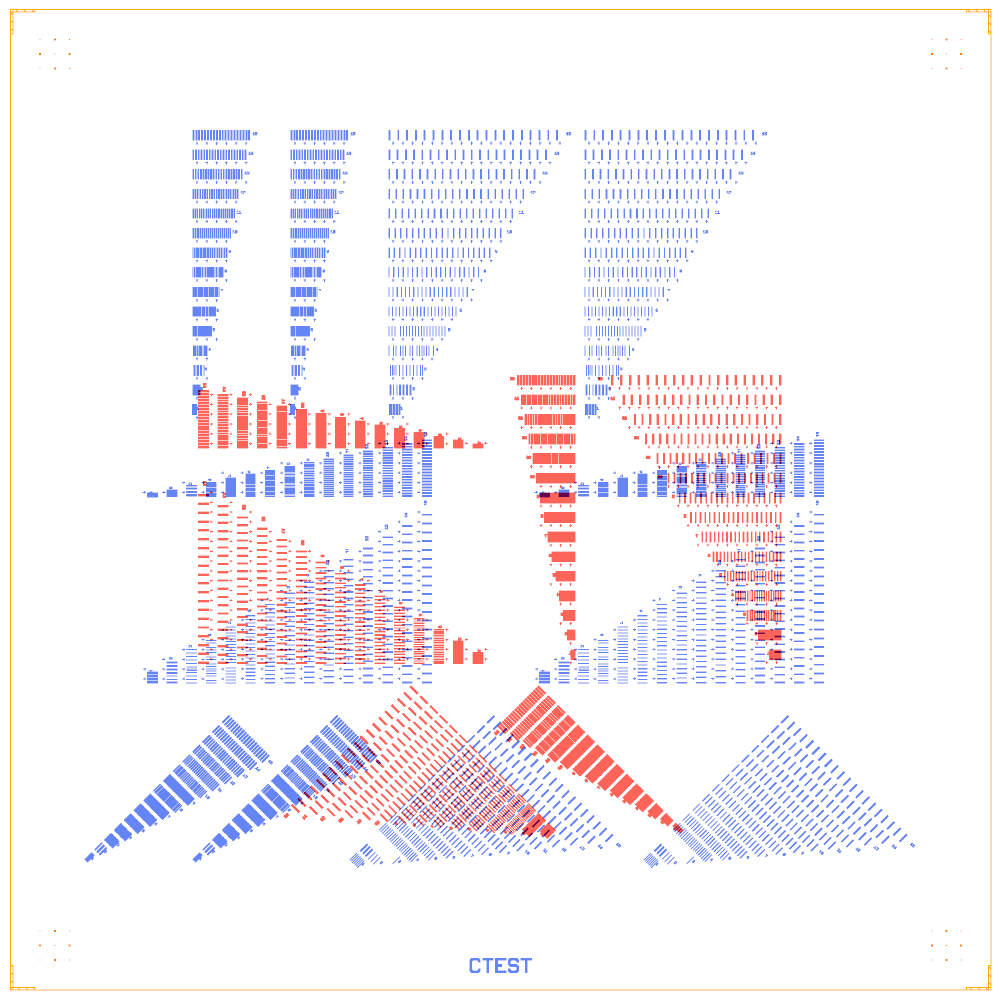

**On the chip so far:** 0 pads · 0 qubits · 1 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `CHIP`.

**`LithographyTestTwoface`** parameters:

| parameter | default | this design | meaning |
|---|---|---|---|
| `stripe_test` | stripe_test | (default) | stripe test type |
| `frames_enabled` | [0, 1] | [] | List of face ids (integers) for which a ChipFrame is drawn |

In [6]:
d.add("CHIP", "LithographyTestTwoface", at=(0, 0), frames_enabled=[])   # KQC chip PCell, no KQC frame
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "lithography_test_twoface.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "1_chip.png", **CHIP)
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift): the views use it
display(Markdown(pcell_params_md("LithographyTestTwoface", d.data["instances"]["CHIP"]["params"])))

## Design 3 · Bond pads: none on this chip

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`edge="auto"` on a pad instance). This chip has no pad instances and no launchers (the table below is empty): any probe pads belong to KQC's drawing of the cell, so the rule has nothing to place.

There are no routes either (no RF lines on this chip); the one component is the chip cell of Design 2.

In [7]:
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

## Design 4 · A view: the horizontal line blocks

`LithographyTestTwoface` builds its line blocks with `create_pattern` (KQC source): for each line width w = 1, 2, … 15 µm a
`StripesTest` block of 20 lines 100 µm long with a gap of 1 × w (the first pattern) or 5 × w (the second), its width
written beside it and a row of `CrossTest` alignment crosses every 100 µm under it. KQC's *horizontal* set stacks the
15 blocks of a pattern 200 µm apart and is placed four times on the bottom chip: the 1 × pattern at x = 2000 and 3000 µm, the
5 × pattern at 4000 and 6000 µm, from y = 6500 µm (the cell's frame; `stripe_test` in Design 2's table picks plain
blocks). The first picture shows the four columns, the second the 1 and 2 µm blocks of the first column.

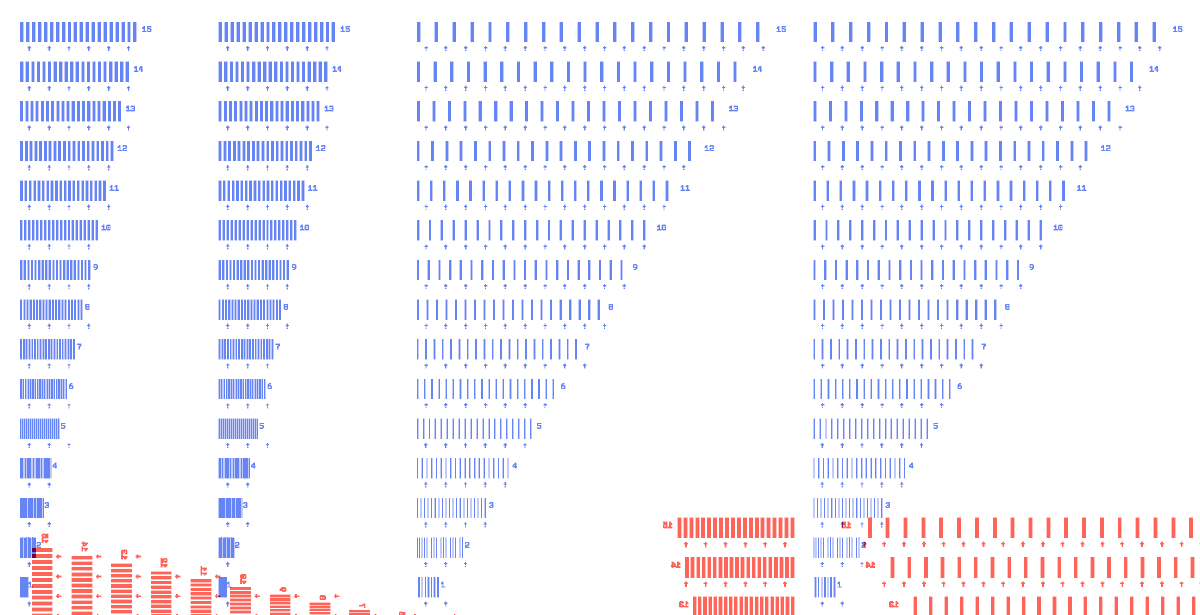

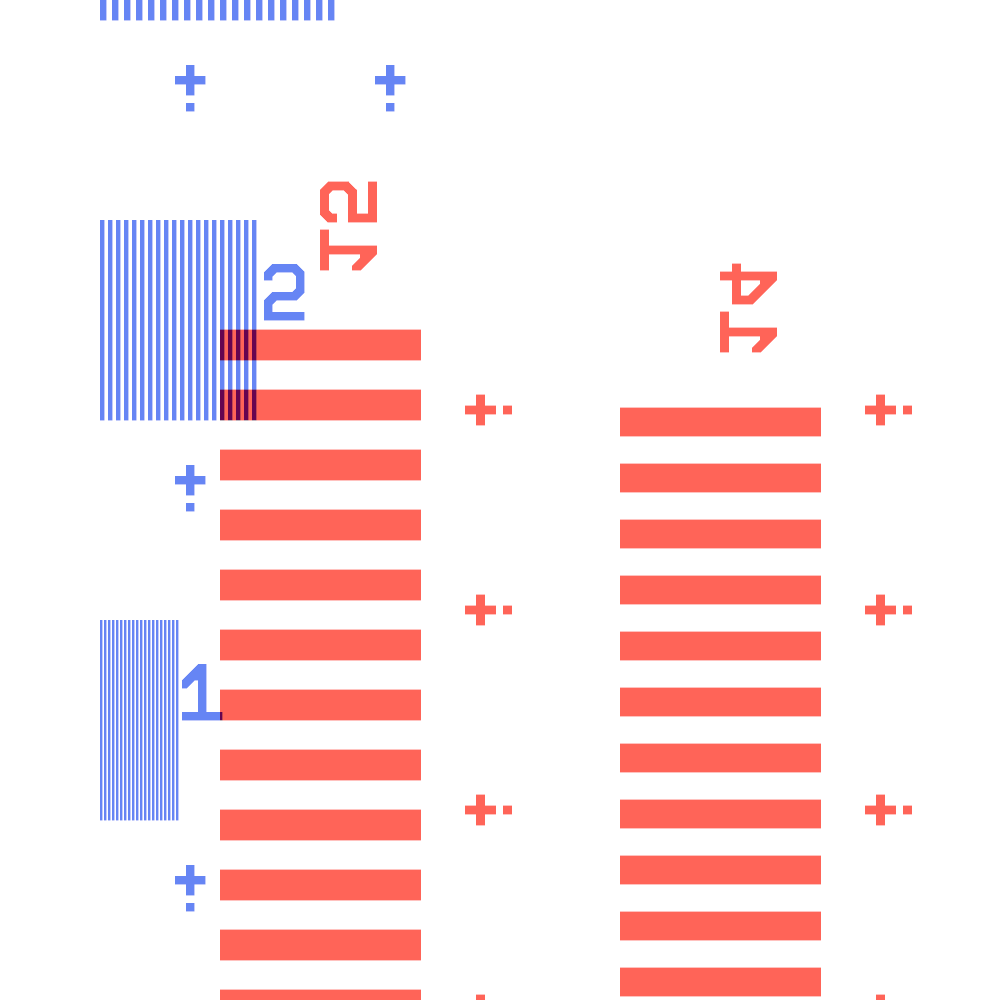

In [8]:
snap(d, STEPS / "s4_horizontal.png", box=(X0 + 1900, Y0 + 6450, X0 + 7950, Y0 + 9550), size=(1200, 615), width=600)
snap(d, STEPS / "s4_horizontal_1um.png", box=(X0 + 1950, Y0 + 6450, X0 + 2450, Y0 + 6950), size=(1000, 1000), width=420);

## Design 5 · A view: the vertical line blocks

The *vertical* set: the same blocks turned by 90° and set side by side 200 µm apart, so their lines run along x;
placed at (1500, 5700) and (5500, 5700) µm for the 1 × pattern and (1500, 3800) and (5500, 3800) µm for the 5 ×
pattern (the cell's frame).

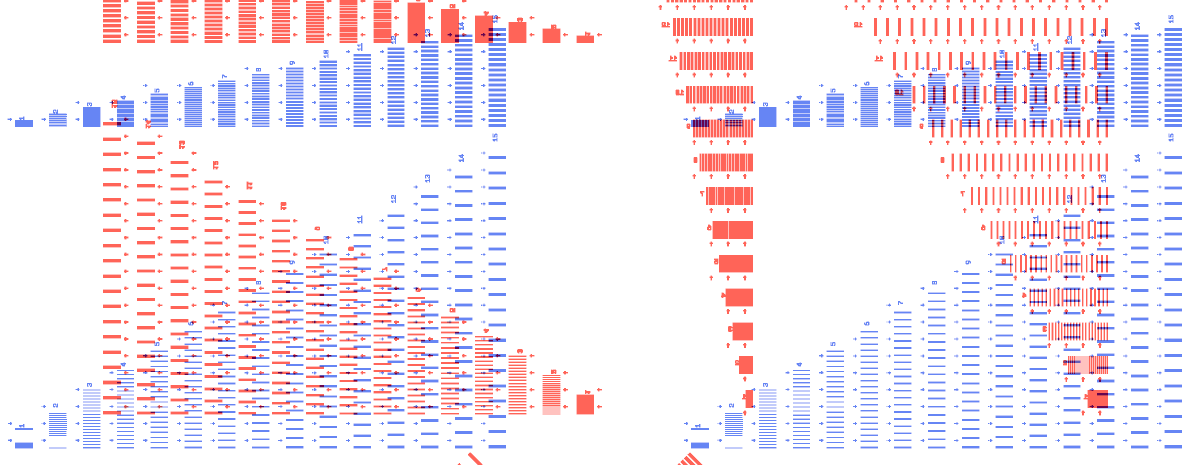

In [9]:
snap(d, STEPS / "s5_vertical.png", box=(X0 + 1450, Y0 + 3700, X0 + 8550, Y0 + 6450), size=(1200, 465), width=600);

## Design 6 · A view: the diagonal line blocks

The *diagonal* set: the blocks turned by −45° and stepped by (100, 100) µm along a diagonal, so the lines run off the
writer's axes; placed at (400, 1500) and (1500, 1500) µm (1 ×) and (3100, 1500) and (6100, 1500) µm (5 ×). The
picture zooms on the two 1 × sets.

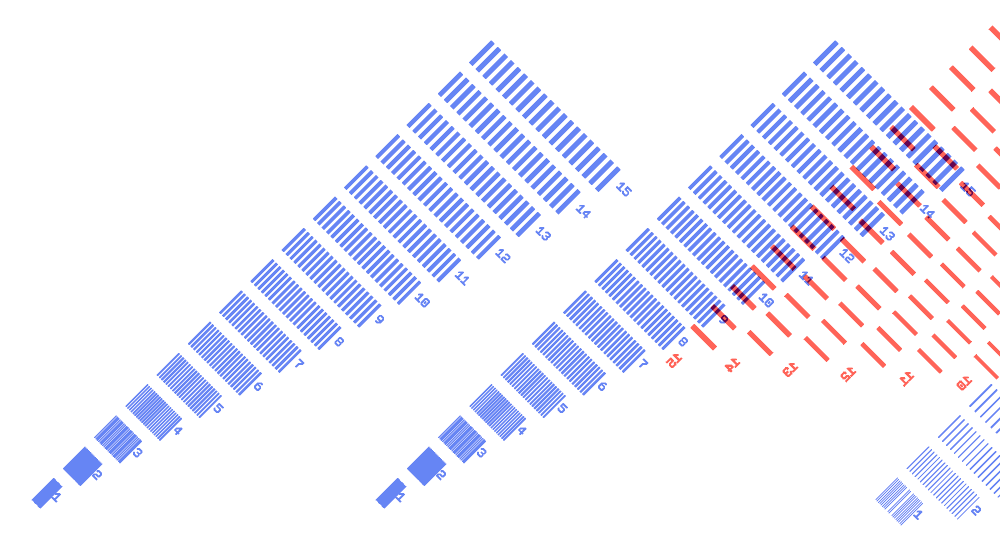

In [10]:
snap(d, STEPS / "s6_diagonal.png", box=(X0 + 800, Y0 + 1850, X0 + 4000, Y0 + 3600), size=(1000, 547), width=480);

## Design 7 · A view: the top chip's mirrored blocks

The top chip (face `2b1`, drawn red) carries one copy of each set and pattern, mirrored (KQC `DCplxTrans.M90`) as it
is seen from below after the flip: the horizontal sets at (5900, 4000) and (8000, 4000) µm, the vertical sets at
(5000, 6200) and (5000, 4000) µm, the diagonal sets at (7500, 1800) and (6200, 1800) µm (the cell's frame). Its etch
goes to 800/0 in the fab export (Fab 1). The picture shows the two mirrored horizontal sets.

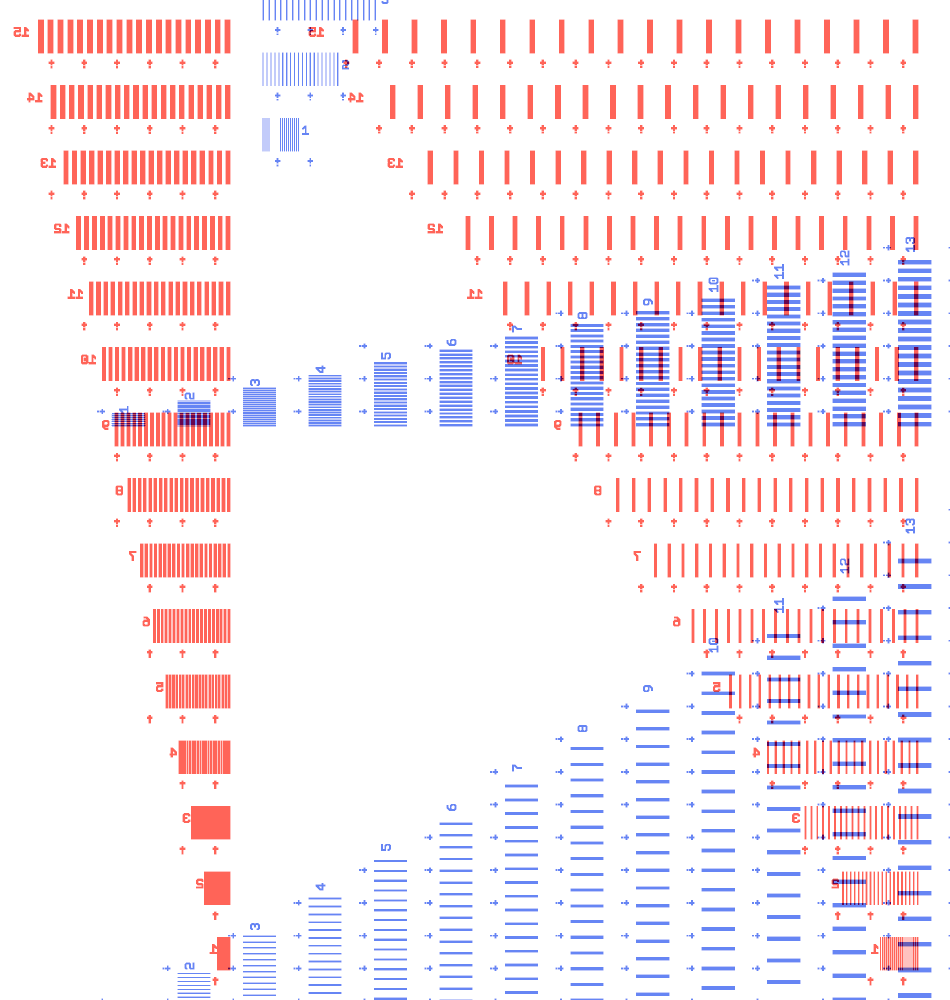

In [11]:
snap(d, STEPS / "s7_top_chip.png", box=(X0 + 5200, Y0 + 3950, X0 + 8100, Y0 + 7000), size=(950, 1000), width=420);

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean: no errors, no warnings (the cell keeps clear of the Quantcore frame) and no PDK design warning; `pdk_report` gives no cheese, the content centred (0, 0) after the shift and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models. No component here has one (the
chip is a process test structure), so the netlist is ground only.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: nothing to simulate

There are no junctions, qubits or resonators, so there is nothing to simulate. The chip is measured in the process
(optical / EBL inspection, DC probing), not with microwaves.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: nothing to export

The design has no sim groups (a process structure has nothing for a C-matrix, eigenmode or driven solve), so the
export below writes no FEM job, and the switches at the top change nothing here.

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Results: no feedback loop

There is no simulated quantity and no target: `LithographyTestTwoface` is a fixed test pattern. A variant is a new KQC parameter set for the cell (Design 2's table), a new design checked in the
fab view and against KQC by the XOR (Fab 2), not a knob to iterate here.

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `lithography_test_twoface.json` (saved in Design 2) is the whole design: `qcc build
examples/designs/kqc/test_chips/lithography_test_twoface.json` rebuilds `build/lithography_test_twoface.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers; the top chip's etch goes to 800/0,
and the frame (100/0, 1000/0, 1001/0). In the v1 run: 1/0 5485 polygons, 3/0 13, 800/0 2740 (the top chip's blocks); cheese source `original`, 0 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/lithography_test_twoface.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip, both faces drawn (bottom face blue, top face red); the die frame's south-west corner (dicing L on 1000/0,
3 × 3 alignment grid on 1001/0); and the first stripe blocks (1 and 2 µm lines with their labels) and, over them, the top chip's mirrored blocks (800/0) in the **fab view** (the mask from Fab 1). The chip
boundary 100/0 is drawn as an outline.

In [ ]:
X0, Y0 = d.data["instances"]["CHIP"]["place"]["at"]   # the cell's origin (after the centring shift)
show_snapshot(d, OUT / "lithography_test_twoface.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "lithography_test_twoface_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "lithography_test_twoface_fab.oas", OUT / "lithography_test_twoface_fab.png", box=(X0 + 1950, Y0 + 6450, X0 + 2450, Y0 + 6950), size=(1200, 1200), width=420);

**Reference: XOR with the source.** KQC's `LithographyTestTwoface` built stand-alone (with KQC's own frame), XOR-ed layer by layer
with this build (`refpoints` and the `instance_names` label layer are annotation and are skipped). **The rebuild is
expected to differ** by design in the frame (KQC's ChipFrame vs the Quantcore die frame), the centring shift and the ground grid (KQC's stand-alone build has none). A
reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.lithography_test_twoface import LithographyTestTwoface
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(LithographyTestTwoface.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "lithography_test_twoface_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
by_name = {ly.get_info(i).name: i for i in ly.layer_indexes()}
rows, total = ["| layer | XOR area (µm²) |", "|---|---|"], 0.0
for li in ref.layer_indexes():
    info = ref.get_info(li)
    a = kdb.Region(ref_top.begin_shapes_rec(li)).merged()
    if a.is_empty() or info.name in ("refpoints", "instance_names"):
        continue
    b = kdb.Region(top.begin_shapes_rec(by_name[info.name])).merged() if info.name in by_name else kdb.Region()
    x = (a ^ b).area() * ref.dbu ** 2
    total += x
    rows.append(f"| {info.name} ({info.layer}/{info.datatype}) | {x:.3g} |")
display(Markdown("\n".join(rows) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "lithography_test_twoface_kqc_original.oas", OUT / "lithography_test_twoface_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**From the v1 run:** the XOR (6.2 × 10⁷ µm²) is KQC's frames on both faces (EBL, avoidance, dicing and airbridge-marker layers) and the centring shift: the base etch differs by 1.44 × 10⁷ µm² on the bottom chip and 7.6 × 10⁶ µm² on the top chip, the frames plus the line patterns drawn 142.6 / 670.1 µm away from KQC's position.

## Summary

| | |
|---|---|
| **matches the source** | the whole `LithographyTestTwoface` cell (KQC's own `build()`) |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the PDK fab layer map; the content centred (the cell moved by (−142.6, −670.1) µm); no cheese, as in the source |
| **not applicable** | the pad rule (no pad instances), routes, LOM, the iterate step, FEM |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | the empty die, the chip cell placed (one KQC PCell, saved there), the pad check, then 4 view(s) of its parts (the horizontal, vertical and diagonal line blocks of the bottom chip and the top chip's mirrored blocks); the saved JSON is the v1 notebook's |
| feedback | none: a fixed test pattern, no simulated quantity |
| open | the view boxes are read off the v1 run's pictures: adjust one if it misses its part |